# MVP – Random Forest para prever aprovação de CAOL

Projeto de Machine Learning (FATEC Mauá – DSM). **Fase 1: MVP no Google Colab.**

**Contexto.** O CAOL (Certificado de Acreditação de Origem Legal) comprova a origem legal de produtos da pesca e é emitido pela PNIP (Ministério da Pesca e Aquicultura). Casanova et al. (2026) propõem um agente com MCP + RAG + CBR; o módulo CBR olha os 5 casos mais parecidos (equivale a um k-NN com k = 5) e atingiu precisão de 0,61, sem comparar com outros modelos.

**Objetivo.** Treinar um Random Forest para prever se um pedido será `aprovado` ou `rejeitado`, comparar com k-NN (k = 5) nas mesmas condições e ver quais atributos mais pesam. O modelo é apoio à decisão: a decisão final é sempre humana.

> **Atenção – dados simulados.** A base real (250 CAOLs anonimizados) não é pública. Usamos uma base simulada, então nossas métricas **não são comparáveis** ao 0,61 do artigo. A comparação válida é **Random Forest x k-NN na nossa base**.

### Regras usadas para gerar o rótulo (`status`)
A probabilidade de rejeição vem de uma função logística sobre um escore de risco, e o rótulo é sorteado dessa probabilidade (ruído). O intercepto é calibrado para ficar perto de 30% de rejeitados. O escore soma:

| Regra | Efeito no risco |
|---|---|
| `acquisition_method == "Importação"` e espécie nativa (Pirarucu, Tambaqui) | +2,0 |
| `acquisition_method == "Extração"` e `haul_days` > 20 | +1,5 |
| `region == "Norte"` e `acquisition_method == "Extração"` e espécie Pirarucu | +1,2 |
| `quantity_kg` alta (acima de 5.000 kg) | +1,0 |
| `product_type == "Pescado salgado"` e `quantity_kg` > 2.000 | +0,8 |
| Ruído gaussiano (desvio 0,8) | aleatório |

Pedidos "pendentes" ficam fora do treino. Nenhum atributo pós-análise (tipo de despacho, pendências do analista) é usado.

## 0. Configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
N_RECORDS = 250

## 1. Geração da base simulada
250 registros com `random_state=42`. A função `calibrate_intercept` ajusta o intercepto por bisseção para a taxa média de rejeição ficar em ~30%.

In [2]:
PRODUCT_TYPES = ["Peixe fresco", "Peixe congelado", "Filé", "Camarão", "Pescado salgado"]
SPECIES = ["Tilápia", "Tambaqui", "Pirarucu", "Sardinha", "Camarão-rosa", "Atum"]
METHODS = ["Extração", "Aquicultura", "Importação"]
REGIONS = ["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]
NATIVE_SPECIES = {"Pirarucu", "Tambaqui"}


def risk_score(df: pd.DataFrame) -> np.ndarray:
    """Escore de risco de rejeição (regras documentadas no topo)."""
    score = np.zeros(len(df))
    imp_native = (df["acquisition_method"] == "Importação") & df["species"].isin(NATIVE_SPECIES)
    long_extraction = (df["acquisition_method"] == "Extração") & (df["haul_days"] > 20)
    north_pirarucu = (
        (df["region"] == "Norte")
        & (df["acquisition_method"] == "Extração")
        & (df["species"] == "Pirarucu")
    )
    big_qty = df["quantity_kg"] > 5000
    salted_big = (df["product_type"] == "Pescado salgado") & (df["quantity_kg"] > 2000)
    score += 2.0 * imp_native + 1.5 * long_extraction + 1.2 * north_pirarucu
    score += 1.0 * big_qty + 0.8 * salted_big
    return score


def calibrate_intercept(score: np.ndarray, target: float = 0.30) -> float:
    """Acha o intercepto que deixa a probabilidade média de rejeição ~ target."""
    lo, hi = -20.0, 20.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if (1 / (1 + np.exp(-(score + mid)))).mean() > target:
            hi = mid
        else:
            lo = mid
    return (lo + hi) / 2


def generate_synthetic(n: int = N_RECORDS, seed: int = RANDOM_STATE) -> pd.DataFrame:
    """Gera a base simulada de CAOLs (aprovado/rejeitado)."""
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({
        "product_type": rng.choice(PRODUCT_TYPES, n),
        "species": rng.choice(SPECIES, n),
        "acquisition_method": rng.choice(METHODS, n, p=[0.45, 0.35, 0.20]),
        "region": rng.choice(REGIONS, n),
        "quantity_kg": np.round(rng.lognormal(mean=7.0, sigma=1.0, size=n), 1),
        "haul_days": rng.integers(1, 31, n),
    })
    score = risk_score(df) + rng.normal(0, 0.8, n)  # ruído
    intercept = calibrate_intercept(score)
    p_reject = 1 / (1 + np.exp(-(score + intercept)))
    df["status"] = np.where(rng.random(n) < p_reject, "rejeitado", "aprovado")
    return df


df = generate_synthetic()
df.to_csv("caol_synthetic.csv", index=False)  # no Colab, fica em /content (copie para o Drive se quiser)
df.head()

,product_type,species,acquisition_method,region,quantity_kg,haul_days,status
0,Peixe fresco,Tambaqui,Aquicultura,Centro-Oeste,1836.1,18,rejeitado
1,Camarão,Pirarucu,Importação,Sul,615.5,29,rejeitado
2,Camarão,Tambaqui,Aquicultura,Sudeste,3922.4,16,rejeitado
3,Filé,Tambaqui,Extração,Centro-Oeste,585.5,15,aprovado
4,Filé,Sardinha,Extração,Norte,580.2,3,aprovado


Pedidos pendentes não entram no treino. Na base simulada não há pendentes, mas o filtro fica explícito para espelhar o fluxo real.

In [3]:
df = df[df["status"].isin(["aprovado", "rejeitado"])].reset_index(drop=True)
print(df.shape)
df["status"].value_counts()

(250, 7)


status
aprovado     181
rejeitado     69
Name: count, dtype: int64

## 2. Análise exploratória
Balanceamento das classes e distribuição dos atributos.

status
aprovado     0.724
rejeitado    0.276
Name: count, dtype: float64


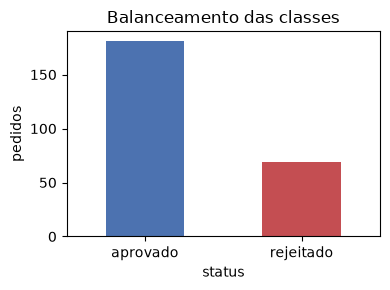

In [4]:
counts = df["status"].value_counts()
print((counts / len(df)).round(3))

fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Balanceamento das classes")
ax.set_ylabel("pedidos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

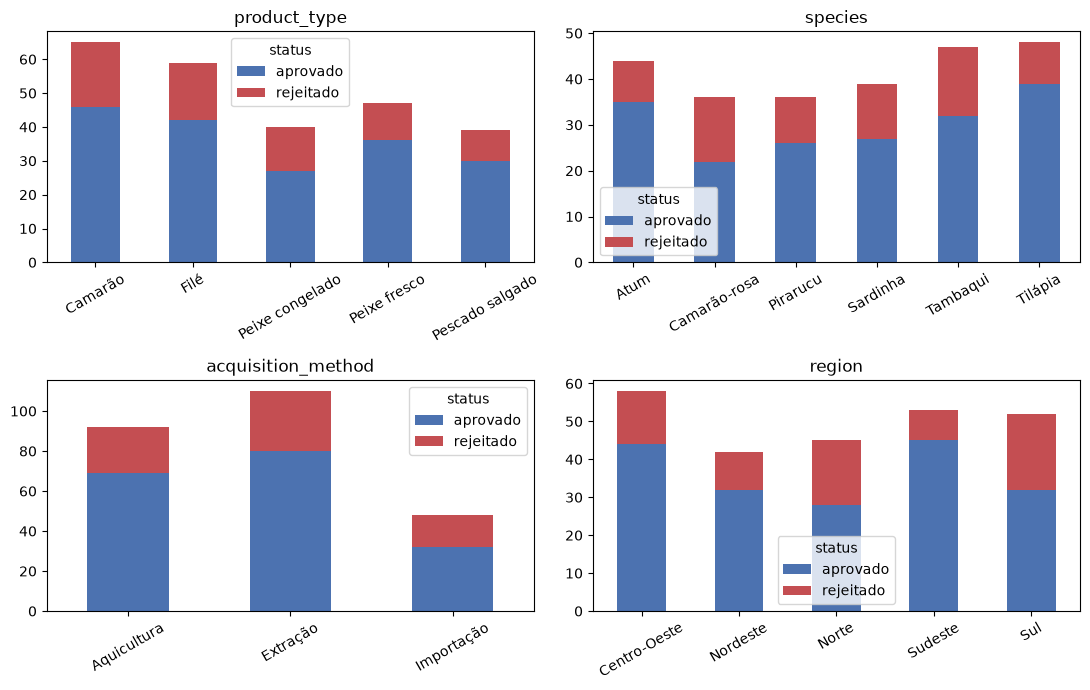

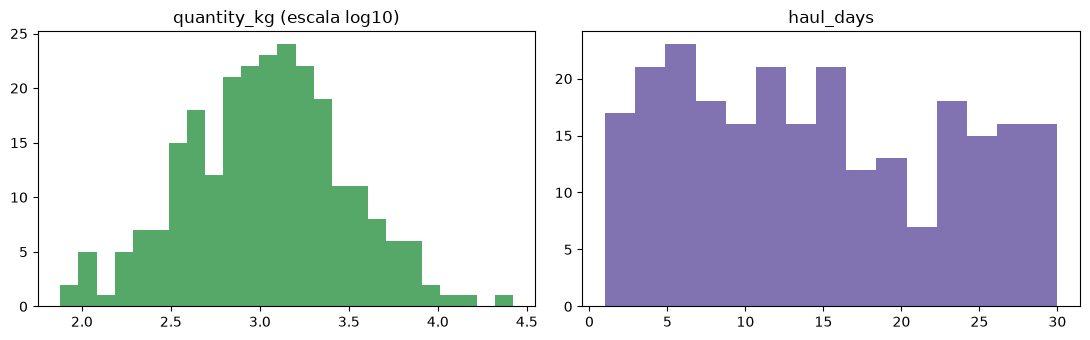

In [5]:
cat_cols = ["product_type", "species", "acquisition_method", "region"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    pd.crosstab(df[col], df["status"]).plot.bar(ax=ax, stacked=True, color=["#4C72B0", "#C44E52"])
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(np.log10(df["quantity_kg"]), bins=25, color="#55A868")
axes[0].set_title("quantity_kg (escala log10)")
axes[1].hist(df["haul_days"], bins=15, color="#8172B2")
axes[1].set_title("haul_days")
plt.tight_layout()
plt.show()

## 3. Pré-processamento
`ColumnTransformer` dentro de um `Pipeline`: one-hot nos categóricos e `StandardScaler` nos numéricos. Como ele fica dentro do pipeline, é ajustado **só no treino de cada fold** (sem vazamento).

O alvo é codificado com **1 = rejeitado** (classe positiva, a minoritária); precisão e recall se referem a ela.

In [6]:
num_cols = ["quantity_kg", "haul_days"]
X = df[cat_cols + num_cols]
y = (df["status"] == "rejeitado").astype(int)


def make_preprocessor() -> ColumnTransformer:
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 4. Random Forest
`class_weight="balanced"` e validação cruzada estratificada de 5 folds.

In [7]:
rf = Pipeline([
    ("prep", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    )),
])
scoring = ["accuracy", "precision", "recall", "f1"]
rf_cv = cross_validate(rf, X, y, cv=cv, scoring=scoring)

## 5. Baseline k-NN (k = 5)
Mesmos folds e mesmo pré-processamento (numéricos escalonados), como o CBR do artigo.

In [8]:
knn = Pipeline([
    ("prep", make_preprocessor()),
    ("model", KNeighborsClassifier(n_neighbors=5)),
])
knn_cv = cross_validate(knn, X, y, cv=cv, scoring=scoring)

## 6. Tabela comparativa
Média ± desvio padrão dos 5 folds (classe positiva: rejeitado).

In [9]:
def summarize(cv_result: dict, name: str) -> dict:
    row = {"modelo": name}
    for m in scoring:
        v = cv_result[f"test_{m}"]
        row[m] = f"{v.mean():.3f} ± {v.std():.3f}"
    return row


results = pd.DataFrame([summarize(rf_cv, "Random Forest"), summarize(knn_cv, "k-NN (k=5)")]).set_index("modelo")
results

,accuracy,precision,recall,f1
modelo,,,,
Random Forest,0.628 ± 0.070,0.329 ± 0.110,0.262 ± 0.060,0.282 ± 0.057
k-NN (k=5),0.676 ± 0.027,0.267 ± 0.165,0.129 ± 0.083,0.171 ± 0.107


## 7. Gráficos
Matriz de confusão (predições fora da amostra, obtidas com os mesmos folds) e importância dos atributos do Random Forest.

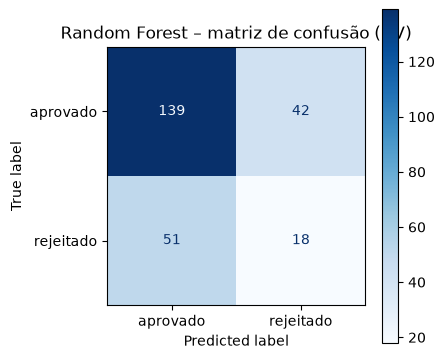

In [10]:
rf_pred = cross_val_predict(rf, X, y, cv=cv)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y, rf_pred, display_labels=["aprovado", "rejeitado"], cmap="Blues", ax=ax
)
ax.set_title("Random Forest – matriz de confusão (CV)")
plt.tight_layout()
plt.show()

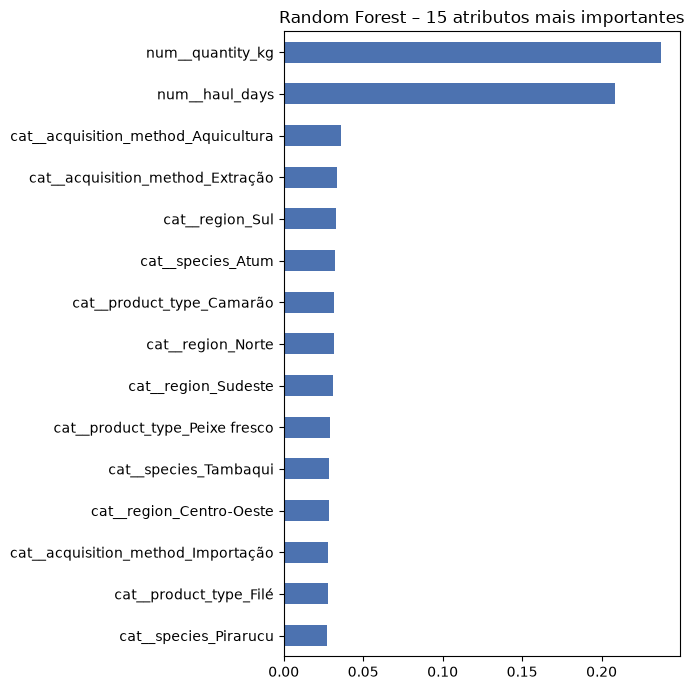

quantity_kg           0.237
haul_days             0.209
species               0.166
region                0.148
product_type          0.142
acquisition_method    0.098
dtype: float64

In [11]:
rf.fit(X, y)  # ajuste final só para inspecionar importâncias
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values()

fig, ax = plt.subplots(figsize=(7, 7))
imp.tail(15).plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Random Forest – 15 atributos mais importantes")
plt.tight_layout()
plt.show()

# Importância agregada por atributo original
orig = imp.groupby(lambda n: n.split("__", 1)[1].rsplit("_", 1)[0] if n.startswith("cat__") else n.split("__", 1)[1]).sum()
orig.sort_values(ascending=False).round(3)

## 8. Conclusões
O texto abaixo é montado a partir dos números desta execução. Nada é escrito à mão.

In [12]:
f1_rf = rf_cv["test_f1"].mean()
f1_knn = knn_cv["test_f1"].mean()
winner = "Random Forest" if f1_rf > f1_knn else "k-NN (k=5)"
top = orig.sort_values(ascending=False).head(3)

print(f"F1 (rejeitado) – Random Forest: {f1_rf:.3f} | k-NN: {f1_knn:.3f} -> melhor: {winner}")
print("Atributos de maior peso no Random Forest:", ", ".join(f"{k} ({v:.2f})" for k, v in top.items()))
print()
print("Limitações:")
print("- Base simulada: os números NÃO são comparáveis ao 0,61 do artigo; só vale RF x k-NN aqui.")
print("- Os atributos mais importantes refletem as regras que nós mesmos usamos para gerar o rótulo.")
print("- Só 250 registros: o desvio padrão entre folds é alto e as diferenças podem não ser significativas.")
print("- Modelo é apoio à decisão; a decisão final é sempre humana.")

F1 (rejeitado) – Random Forest: 0.282 | k-NN: 0.171 -> melhor: Random Forest
Atributos de maior peso no Random Forest: quantity_kg (0.24), haul_days (0.21), species (0.17)

Limitações:
- Base simulada: os números NÃO são comparáveis ao 0,61 do artigo; só vale RF x k-NN aqui.
- Os atributos mais importantes refletem as regras que nós mesmos usamos para gerar o rótulo.
- Só 250 registros: o desvio padrão entre folds é alto e as diferenças podem não ser significativas.
- Modelo é apoio à decisão; a decisão final é sempre humana.
